# Toric Code  $[[2L^2,\, 2,\, L]]$

**Location:** `Qubit Codes / Stabilizer Codes / CSS Codes / Topological Codes / Toric_Code.ipynb`

**Primary reference:** A. N. Cleland, *SciPost Phys. Lect. Notes* **49** (2022) — §1 Overview, §6 Introduction to the surface code.
**Original source:** A. Kitaev, *Ann. Phys.* **303**, 2 (2003); preprint (1997).

---

## Contents
1. [Physical intuition](#1-physical-intuition)
2. [Formal definition](#2-formal-definition)
3. [Code parameters](#3-code-parameters)
4. [Logical operators](#4-logical-operators)
5. [Anyonic excitations](#5-anyonic-excitations)
6. [L = 2 worked example](#6-l--2-worked-example)


## 1. Physical Intuition

The **surface code** — the leading hardware candidate for fault-tolerant quantum computing — descends directly from the **toric code**, invented by Kitaev (1997).

> *"The surface codes originated in the toric codes, invented by Alexei Kitaev [1-3], which in turn evolved from Kitaev's models for supporting topological order, using qubits distributed on the surface of a toroid, a two-dimensional surface with periodic boundary conditions along both in-plane directions. Kitaev's toroidal geometry ultimately turned out to be unnecessary, and the planar versions, known as the surface codes, were primarily developed by Bravyi and Kitaev as well as Freedman and Meyer [4, 5]."*
> — Cleland (2022), §1 Overview, p. 3

The essential idea is topological:

- Place $2L^2$ physical qubits on the **edges** of an $L \times L$ square lattice with periodic boundary conditions in both directions (a torus $\mathbb{T}^2$).
- Define **$X$-stabilizers** (star operators) at each vertex and **$Z$-stabilizers** (plaquette operators) at each face.
- The codespace is the simultaneous $+1$ eigenspace of all stabilizers.
- **Logical information** is encoded in **non-contractible loops** — closed paths winding around the torus that cannot be continuously shrunk to a point.

The toroidal geometry makes every vertex and every face equivalent: there are no boundaries. The surface code is the planar variant that opens the boundaries, trading one topological class for a rectangle.

```
  L=3 toric lattice (schematic; arrows indicate periodic identification)

   --o--o--o-->  (x-direction, periodic)
   |  |  |  |
   o--o--o--o    qubit on each edge
   |  |  |  |    vertex o  ->  X-stabilizer (star)
   o--o--o--o    face   []  ->  Z-stabilizer (plaquette)
   |  |  |  |
   v           (y-direction, periodic)
```


## 2. Formal Definition

### Lattice

Consider an $L \times L$ square lattice on the torus $\mathbb{T}^2$. Index vertices by $(i,j)$ with $i,j \in \mathbb{Z}_L$ (all arithmetic mod $L$).

- **Horizontal edge** $(i,j)_h$: connects $(i,j)$ to $(i{+}1,j)$. Qubit index $q(i,j,0)$.
- **Vertical edge** $(i,j)_v$: connects $(i,j)$ to $(i,j{+}1)$. Qubit index $q(i,j,1)$.

Total edges: $n = 2L^2$.

### Stabilizer generators

The toric code is a **CSS code** — stabilizers decompose cleanly into $X$-type and $Z$-type:

$$A_v = \prod_{e \ni v} X_e \qquad (\text{vertex star, } X\text{-type})$$

$$B_f = \prod_{e \in \partial f} Z_e \qquad (\text{face plaquette, }Z\text{-type})$$

| Type | Operator | Touching/bounding edges | Detects |
|------|----------|------------------------|---------|
| Vertex star $A_v$ | $\prod_{e \ni v} X_e$ | 4 edges incident to $v$ | $Z$-type errors |
| Face plaquette $B_f$ | $\prod_{e \in \partial f} Z_e$ | 4 edges bounding $f$ | $X$-type errors |

There are $L^2$ of each, but each set has one global dependency:

$$\prod_v A_v = I, \qquad \prod_f B_f = I.$$

This leaves $L^2 - 1$ independent generators of each type.

**CSS compatibility** $H_X H_Z^T = 0 \pmod{2}$: every vertex and face share exactly 0 or 2 edges (even overlap), so all $A_v$ and $B_f$ commute.


## 3. Code Parameters

$$\boxed{[[n,\, k,\, d]] = [[2L^2,\, 2,\, L]]}$$

| Parameter | Value | Explanation |
|-----------|-------|-------------|
| $n$ | $2L^2$ | physical qubits (one per edge) |
| $k$ | $2$ | logical qubits (one per independent non-contractible cycle class) |
| $d$ | $L$ | code distance (minimum-weight logical operator) |
| $m_X$ | $L^2 - 1$ | independent $X$-type checks |
| $m_Z$ | $L^2 - 1$ | independent $Z$-type checks |
| $m_{\rm total}$ | $2(L^2-1)$ | total independent stabilizer generators |

**Encoding rate:** $k/n = 1/L^2 \to 0$ (vanishing rate, typical of all topological codes).

**Why $k=2$?** The torus $\mathbb{T}^2$ has exactly two independent non-contractible 1-cycles.  Via the Euler characteristic $V - E + F = L^2 - 2L^2 + L^2 = 0$:

$$k = n - \operatorname{rank}(H_X) - \operatorname{rank}(H_Z) = 2L^2 - (L^2-1) - (L^2-1) = 2. \checkmark$$


## 4. Logical Operators

Each of the two encoded logical qubits has an anti-commuting $\bar X / \bar Z$ pair. These are **non-contractible loops** on either the primal lattice or its dual.

The dual lattice is offset by $(\tfrac{1}{2}, \tfrac{1}{2})$: its edges cross the primal edges perpendicularly. A horizontal dual edge crosses a vertical primal edge; a vertical dual edge crosses a horizontal primal edge.

| Operator | Pauli | Loop type | Primal edge type |
|----------|-------|-----------|------------------|
| $\bar{X}_1$ | $X$ | dual horizontal ($y=0$) | vertical primal, $j=0$: all $q(i,0,1)$ |
| $\bar{Z}_1$ | $Z$ | primal vertical ($x=0$) | vertical primal, $i=0$: all $q(0,j,1)$ |
| $\bar{X}_2$ | $X$ | dual vertical ($x=0$) | horizontal primal, $i=0$: all $q(0,j,0)$ |
| $\bar{Z}_2$ | $Z$ | primal horizontal ($y=0$) | horizontal primal, $j=0$: all $q(i,0,0)$ |

**Anti-commutativity:** $\bar X_1$ and $\bar Z_1$ share the single qubit $q(0,0,1)$  (odd overlap $\Rightarrow$ anti-commute). Similarly $\bar X_2$ and $\bar Z_2$ share only $q(0,0,0)$.  Cross-pairs $\{\bar X_1, \bar Z_2\}$ and $\{\bar X_2, \bar Z_1\}$ share no qubits (commute).

**Distance $d=L$:** the shortest non-contractible loop on an $L\times L$ torus visits exactly $L$ edges.  Any stabilizer-equivalent deformation preserves the logical action — topology protects the encoding.


## 5. Anyonic Excitations

Errors create **check violations** — the only information the decoder receives.

| Error on edge $e$ | Violated stabilizers | Excitation |
|-------------------|----------------------|------------|
| $X_e$ | Both **faces** adjacent to $e$ | Pair of $\mathbf{e}$-anyons (electric) |
| $Z_e$ | Both **vertices** adjacent to $e$ | Pair of $\mathbf{m}$-anyons (magnetic) |
| $Y_e = iX_eZ_e$ | Adjacent faces **and** vertices | Composite $\boldsymbol{\varepsilon}$-anyon |

**Key properties:**

- Errors always create anyons in *pairs* — a single isolated excitation requires traversing a length-$L$ path (weight $d$), an exponentially unlikely event.
- Moving an $\mathbf{e}$-anyon around an $\mathbf{m}$-anyon accumulates a $-1$ phase: they are mutual semions.
- A logical error = dragging an anyon around a full non-contractible loop until annihilation with its partner; probability $\propto e^{-\alpha L}$, exponentially suppressed.

**Syndrome** $= \{s_v\} \cup \{s_f\} \in \{+1,-1\}^{2(L^2-1)}$: which checks are violated.  
**Decoding** = infer the most likely error from the syndrome (minimum-weight perfect matching on the anyon-pair graph).


## 6. $L = 2$ Worked Example

Smallest non-trivial toric code: **$[[8, 2, 2]]$**.

**Qubit indexing:** $q(i,j,d) = 2\bigl((j\bmod L)\cdot L + (i \bmod L)\bigr) + d$,  $\;d=0$ horizontal, $d=1$ vertical.

```
  y=1:  (0,1)--q4--(1,1)--q6--(0,1)
          |q5          |q7         (periodic in y)
  y=0:  (0,0)--q0--(1,0)--q2--(0,0)
          |q1          |q3
        (0,1) <-- periodic in y (wraps back)
         q0,q2 = horizontal edges at y=0
         q4,q6 = horizontal edges at y=1
         q1,q3 = vertical   edges at y=0 to y=1
         q5,q7 = vertical   edges at y=1 to y=0
```

Logical operators (derived from loop topology):
- $\bar X_1 = X_{q1} X_{q3}$,  $\bar Z_1 = Z_{q1} Z_{q5}$  (vertical edges, anti-commute on $q1$)
- $\bar X_2 = X_{q0} X_{q4}$,  $\bar Z_2 = Z_{q0} Z_{q2}$  (horizontal edges, anti-commute on $q0$)


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

L = 2
N = 2 * L * L  # 8 physical qubits

def q(i, j, d):
    """Qubit index for edge at (i mod L, j mod L, d). d=0 horizontal, d=1 vertical."""
    return 2 * ((j % L) * L + (i % L)) + d

# X-type (vertex star) stabilizers
# Vertex (i,j) touches: left h-edge q(i-1,j,0), right h-edge q(i,j,0),
#                        bottom v-edge q(i,j-1,1), top v-edge q(i,j,1)
vertex_stabs = {}
for jj in range(L):
    for ii in range(L):
        vertex_stabs[(ii,jj)] = sorted({q(ii-1,jj,0), q(ii,jj,0),
                                        q(ii,jj-1,1), q(ii,jj,1)})

# Z-type (face plaquette) stabilizers
# Face (i,j) (lower-left corner) bounded by:
#   bottom h-edge q(i,j,0), top h-edge q(i,j+1,0),
#   left v-edge q(i,j,1),   right v-edge q(i+1,j,1)
face_stabs = {}
for jj in range(L):
    for ii in range(L):
        face_stabs[(ii,jj)] = sorted({q(ii,jj,0),   q(ii,jj+1,0),
                                      q(ii,jj,1),   q(ii+1,jj,1)})

print('=== L=2 Toric Code: [[{}, 2, {}]] ===\n'.format(N, L))
print('X-type (vertex) stabilizers:')
for v, s in vertex_stabs.items():
    print('  A_{} = '.format(v) + ' * '.join('X{}'.format(k) for k in s))
print()
print('Z-type (face) stabilizers:')
for f, s in face_stabs.items():
    print('  B_{} = '.format(f) + ' * '.join('Z{}'.format(k) for k in s))

# CSS compatibility check
print()
all_ok = all(len(set(vs) & set(fs)) % 2 == 0
             for vs in vertex_stabs.values()
             for fs in face_stabs.values())
print('CSS check: every vertex-face pair shares 0 or 2 qubits:', all_ok, '(H_X H_Z^T = 0 checkmark)')


=== L=2 Toric Code: [[8, 2, 2]] ===

X-type (vertex) stabilizers:
  A_(0, 0) = X0 * X1 * X2 * X5
  A_(1, 0) = X0 * X2 * X3 * X7
  A_(0, 1) = X1 * X4 * X5 * X6
  A_(1, 1) = X3 * X4 * X6 * X7

Z-type (face) stabilizers:
  B_(0, 0) = Z0 * Z1 * Z3 * Z4
  B_(1, 0) = Z1 * Z2 * Z3 * Z6
  B_(0, 1) = Z0 * Z4 * Z5 * Z7
  B_(1, 1) = Z2 * Z5 * Z6 * Z7

CSS check: every vertex-face pair shares 0 or 2 qubits: True (H_X H_Z^T = 0 checkmark)


In [2]:
def syndrome(err_x, err_z):
    """Return (syn_z, syn_x): vertex and face check violation flags."""
    syn_z = {v: int(sum(err_z[k] for k in s) % 2) for v, s in vertex_stabs.items()}
    syn_x = {f: int(sum(err_x[k] for k in s) % 2) for f, s in face_stabs.items()}
    return syn_z, syn_x

# Example: single X error on qubit 0 = horizontal edge q(0,0,0)
err_x = np.zeros(N, dtype=int)
err_z = np.zeros(N, dtype=int)
err_x[0] = 1

syn_z, syn_x = syndrome(err_x, err_z)

print('Error: X on qubit', np.where(err_x)[0].tolist())
print()
print('Face (Z-plaquette) syndrome  [detects X errors]:')
for f, viol in syn_x.items():
    flag = '  <- VIOLATED' if viol else ''
    sign = '-1' if viol else '+1'
    print('  B_{} = {}{}'.format(f, sign, flag))
print()
print('Vertex (X-star) syndrome  [detects Z errors]:')
for v, viol in syn_z.items():
    flag = '  <- VIOLATED' if viol else ''
    sign = '-1' if viol else '+1'
    print('  A_{} = {}{}'.format(v, sign, flag))
print()
n_viol = sum(syn_x.values())
print('X error on one edge violates {} face check(s)  (expected 2) checkmark'.format(n_viol))


Error: X on qubit [0]

Face (Z-plaquette) syndrome  [detects X errors]:
  B_(0, 0) = -1  <- VIOLATED
  B_(1, 0) = +1
  B_(0, 1) = -1  <- VIOLATED
  B_(1, 1) = +1

Vertex (X-star) syndrome  [detects Z errors]:
  A_(0, 0) = +1
  A_(1, 0) = +1
  A_(0, 1) = +1
  A_(1, 1) = +1

X error on one edge violates 2 face check(s)  (expected 2) checkmark


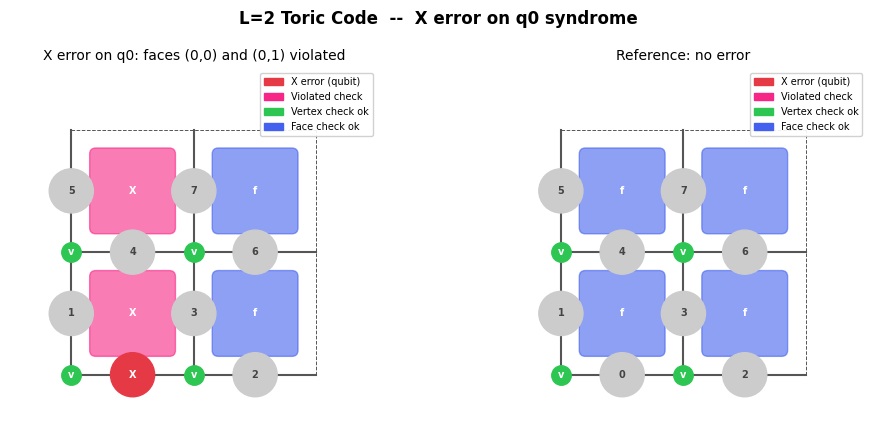

In [3]:
def draw_toric(ax, err_x, err_z, syn_x, syn_z, title):
    ax.set_xlim(-0.5, 2.5); ax.set_ylim(-0.5, 2.5)
    ax.set_aspect('equal'); ax.axis('off')
    ax.set_title(title, fontsize=10)
    # grid lines
    for k in range(L + 1):
        lw = 1.5 if k < L else 0.7
        ls = '-' if k < L else '--'
        ax.plot([k, k], [0, L], color='#555', lw=lw, ls=ls)
        ax.plot([0, L], [k, k], color='#555', lw=lw, ls=ls)
    # qubit positions on edges
    qpos = {}
    for jj in range(L):
        for ii in range(L):
            qpos[q(ii,jj,0)] = (ii + 0.5, jj)      # horizontal edge centre
            qpos[q(ii,jj,1)] = (ii,       jj + 0.5) # vertical edge centre
    for qi, (x, y) in qpos.items():
        hx, hz = err_x[qi], err_z[qi]
        if hx and hz:   c, lbl = '#ff9900', 'Y'
        elif hx:        c, lbl = '#e63946', 'X'
        elif hz:        c, lbl = '#457b9d', 'Z'
        else:           c, lbl = '#ccc',    str(qi)
        ax.add_patch(plt.Circle((x, y), 0.18, color=c, zorder=3))
        ax.text(x, y, lbl, ha='center', va='center', fontsize=7,
                color='white' if (hx or hz) else '#444',
                fontweight='bold', zorder=4)
    # vertex check markers
    for (ii,jj), viol in syn_z.items():
        c = '#f72585' if viol else '#2dc653'
        ax.plot(ii, jj, 'o', ms=14, color=c, zorder=5)
        ax.text(ii, jj, 'X' if viol else 'v', ha='center', va='center',
                fontsize=7, color='white', fontweight='bold', zorder=6)
    # face check markers
    for (ii,jj), viol in syn_x.items():
        c = '#f72585' if viol else '#4361ee'
        ax.add_patch(mpatches.FancyBboxPatch(
            (ii + 0.2, jj + 0.2), 0.6, 0.6,
            boxstyle='round,pad=0.05', color=c, alpha=0.6, zorder=2))
        ax.text(ii + 0.5, jj + 0.5, 'X' if viol else 'f',
                ha='center', va='center', fontsize=7,
                color='white', fontweight='bold', zorder=3)
    ax.legend(handles=[
        mpatches.Patch(color='#e63946', label='X error (qubit)'),
        mpatches.Patch(color='#f72585', label='Violated check'),
        mpatches.Patch(color='#2dc653', label='Vertex check ok'),
        mpatches.Patch(color='#4361ee', label='Face check ok'),
    ], loc='upper right', fontsize=7, framealpha=0.9)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
fig.suptitle('L=2 Toric Code  --  X error on q0 syndrome',
             fontsize=12, fontweight='bold')
draw_toric(axes[0], err_x, err_z, syn_x, syn_z,
           'X error on q0: faces (0,0) and (0,1) violated')
e0 = np.zeros(N, dtype=int)
sz0, sx0 = syndrome(e0, e0)
draw_toric(axes[1], e0, e0, sx0, sz0, 'Reference: no error')
plt.tight_layout()
plt.savefig('toric_L2_example.png', dpi=130, bbox_inches='tight')
plt.show()


In [4]:
# Logical operators for [[8, 2, 2]] toric code
# X logicals live on dual-lattice loops; Z logicals on primal-lattice loops.
# Crossing topology: X_bar_i and Z_bar_i share exactly 1 qubit (anti-commute).

X_bar_1 = [q(ii,  0, 1) for ii in range(L)]  # dual horiz. loop -> vertical primal edges at y=0
Z_bar_1 = [q(0,  jj, 1) for jj in range(L)]  # primal vert. loop -> vertical primal edges at x=0
X_bar_2 = [q(0,  jj, 0) for jj in range(L)]  # dual vert. loop  -> horizontal primal edges at x=0
Z_bar_2 = [q(ii,  0, 0) for ii in range(L)]  # primal horiz. loop-> horizontal primal edges at y=0

print('Logical operators:')
print('  X_bar_1 = X on {}  (vertical edges at y=0)'.format(X_bar_1))
print('  Z_bar_1 = Z on {}  (vertical edges at x=0)'.format(Z_bar_1))
print('  X_bar_2 = X on {}  (horizontal edges at x=0)'.format(X_bar_2))
print('  Z_bar_2 = Z on {}  (horizontal edges at y=0)'.format(Z_bar_2))
print()

# Anti-commutativity (odd overlap = anti-commute)
ov11 = len(set(X_bar_1) & set(Z_bar_1))
ov22 = len(set(X_bar_2) & set(Z_bar_2))
ov12 = len(set(X_bar_1) & set(Z_bar_2))
ov21 = len(set(X_bar_2) & set(Z_bar_1))
print('Anti-commutativity checks:')
print('  |X1 cap Z1| = {}  -> anti-commute: {} checkmark'.format(ov11, ov11 % 2 == 1))
print('  |X2 cap Z2| = {}  -> anti-commute: {} checkmark'.format(ov22, ov22 % 2 == 1))
print('  |X1 cap Z2| = {}  -> commute (different qubits): {} checkmark'.format(ov12, ov12 % 2 == 0))
print('  |X2 cap Z1| = {}  -> commute (different qubits): {} checkmark'.format(ov21, ov21 % 2 == 0))
print()

# Z logicals must commute with all vertex stars (be in ker H_X)
print('Z_bar_1 commutes with all vertex stars?')
for v, s in vertex_stabs.items():
    ov = len(set(Z_bar_1) & set(s)) % 2
    status = 'ok' if ov == 0 else 'FAIL'
    print('  Z_bar_1 vs A_{}: overlap parity={} [{}]'.format(v, ov, status))
print()
print('Z_bar_2 commutes with all vertex stars?')
for v, s in vertex_stabs.items():
    ov = len(set(Z_bar_2) & set(s)) % 2
    status = 'ok' if ov == 0 else 'FAIL'
    print('  Z_bar_2 vs A_{}: overlap parity={} [{}]'.format(v, ov, status))


Logical operators:
  X_bar_1 = X on [1, 3]  (vertical edges at y=0)
  Z_bar_1 = Z on [1, 5]  (vertical edges at x=0)
  X_bar_2 = X on [0, 4]  (horizontal edges at x=0)
  Z_bar_2 = Z on [0, 2]  (horizontal edges at y=0)

Anti-commutativity checks:
  |X1 cap Z1| = 1  -> anti-commute: True checkmark
  |X2 cap Z2| = 1  -> anti-commute: True checkmark
  |X1 cap Z2| = 0  -> commute (different qubits): True checkmark
  |X2 cap Z1| = 0  -> commute (different qubits): True checkmark

Z_bar_1 commutes with all vertex stars?
  Z_bar_1 vs A_(0, 0): overlap parity=0 [ok]
  Z_bar_1 vs A_(1, 0): overlap parity=0 [ok]
  Z_bar_1 vs A_(0, 1): overlap parity=0 [ok]
  Z_bar_1 vs A_(1, 1): overlap parity=0 [ok]

Z_bar_2 commutes with all vertex stars?
  Z_bar_2 vs A_(0, 0): overlap parity=0 [ok]
  Z_bar_2 vs A_(1, 0): overlap parity=0 [ok]
  Z_bar_2 vs A_(0, 1): overlap parity=0 [ok]
  Z_bar_2 vs A_(1, 1): overlap parity=0 [ok]


## Summary

| Property | Toric Code |
|----------|------------|
| Qubit layout | one qubit per edge of $L\times L$ torus |
| $X$-stabilizers | vertex stars $A_v = \prod_{e\ni v} X_e$ |
| $Z$-stabilizers | face plaquettes $B_f = \prod_{e\in\partial f} Z_e$ |
| CSS structure | $H_X H_Z^T = 0$ (vertex--face even overlap) |
| Parameters | $[[2L^2,\, 2,\, L]]$ |
| $\bar X$ logicals | non-contractible loops on the **dual** lattice |
| $\bar Z$ logicals | non-contractible loops on the **primal** lattice |
| Error syndromes | violated checks = anyon pairs ($\mathbf{e}$ or $\mathbf{m}$) |
| Decoding | minimum-weight perfect matching on the defect graph |
| Relation to surface code | open boundaries $\to$ $[[L^2+(L{-}1)^2,\;1,\;L]]$ (~1% threshold) |

**Next in series:** [`surface_code.ipynb`](surface_code.ipynb) — planar variant, the experimental hardware target  (Cleland 2022, §6 onwards).

---

*Reference: A. N. Cleland, "An introduction to the surface code," SciPost Phys. Lect. Notes **49** (2022), doi:10.21468/SciPostPhysLectNotes.49*
